In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)

FILE = "vgchartz-2024.csv"
SEED = 42

In [9]:
df_all = pd.read_csv(FILE, on_bad_lines="skip")
print("Seluruh dataset :", df_all.shape)
print(df_all["console"].value_counts().head(30))

Seluruh dataset : (64016, 14)
console
PC      12617
PS2      3565
DS       3288
PS4      2878
PS       2707
NS       2337
XBL      2120
PSN      2004
XOne     1963
PS3      1905
PSP      1807
X360     1735
Wii      1676
GBA      1659
GB       1599
SNES     1211
3DS      1192
All      1138
NES      1106
PSV      1105
And      1051
XB        982
GEN       804
DSiW      753
SAT       739
OSX       673
GC        663
VC        661
DC        655
PS5       648
Name: count, dtype: int64


In [10]:
# Sesuaikan kode dengan hasil value_counts() di atas
KONSOL_NINTENDO = ["Wii", "DS", "3DS", "WiiU", "NS"]
df = df_all[df_all["console"].isin(KONSOL_NINTENDO)].copy()
print("Data Nintendo   :", df.shape)
assert len(df) >= 1000, "Kurang dari 1000 baris, cek kode konsol atau tambah konsol"

Data Nintendo   : (9047, 14)


In [11]:
# Kalau baris kembar masuk ke train dan test sekaligus, model "menyontek" dan skornya palsu
n_awal = len(df)
df = df.drop(columns=["img"], errors="ignore").drop_duplicates().reset_index(drop=True)
print(f"Duplikat dibuang: {n_awal - len(df)} baris | sisa: {len(df)}")

Duplikat dibuang: 1 baris | sisa: 9046


In [12]:
n_awal = len(df)
df = df.dropna(subset=["total_sales"]).reset_index(drop=True)
print(f"total_sales kosong dibuang: {n_awal - len(df)} baris | sisa: {len(df)}")

# Split 80% train / 20% test
train_raw, test_raw = train_test_split(df, test_size=0.2, random_state=SEED)
train_raw = train_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)
print("Train:", train_raw.shape, "| Test:", test_raw.shape)

total_sales kosong dibuang: 4321 baris | sisa: 4725
Train: (3780, 13) | Test: (945, 13)


In [13]:
print("Tipe data:"); print(train_raw.dtypes, "\n")
print("Persen kosong per kolom (train, mentah):")
kosong = (train_raw.isnull().mean() * 100).round(1)
print(kosong.sort_values(ascending=False))

Tipe data:
title            object
console          object
genre            object
publisher        object
developer        object
critic_score    float64
total_sales     float64
na_sales        float64
jp_sales        float64
pal_sales       float64
other_sales     float64
release_date     object
last_update      object
dtype: object 

Persen kosong per kolom (train, mentah):
critic_score    83.2
last_update     79.3
jp_sales        65.2
pal_sales       43.6
na_sales        33.3
other_sales     24.4
release_date     0.8
developer        0.0
console          0.0
title            0.0
publisher        0.0
genre            0.0
total_sales      0.0
dtype: float64


In [14]:
SALES_COLS = ["na_sales", "jp_sales", "pal_sales", "other_sales"]

def bersihkan(d, stat=None):
    """Jika stat=None (data TRAIN), statistik dihitung dari data ini.
    Jika stat diberikan (data TEST), pakai statistik dari train."""
    d = d.copy()

    # kolom tidak relevan
    d = d.drop(columns=["last_update"], errors="ignore")

    # samakan format teks
    for c in ["title", "genre", "publisher", "developer", "console"]:
        d[c] = d[c].astype("string").str.strip()
    d["genre"] = d["genre"].fillna("Unknown")
    d["publisher"] = d["publisher"].fillna("Unknown")
    d["developer"] = d["developer"].fillna("Unknown")

    # tanggal -> tahun rilis
    d["release_date"] = pd.to_datetime(d["release_date"], errors="coerce")
    d["release_year"] = d["release_date"].dt.year

    # penjualan regional kosong = tidak ada penjualan tercatat
    d[SALES_COLS] = d[SALES_COLS].fillna(0)

    # penanda "skor kritikus tersedia"
    d["has_critic_score"] = d["critic_score"].notna().astype(int)

    if stat is None:                         # hanya dihitung dari TRAIN
        stat = {
            "median_year": d["release_year"].median(),
            "median_score": d["critic_score"].median(),
            "top_publisher": d["publisher"].value_counts().head(15).index.tolist(),
            "cap_sales": d["total_sales"].quantile(0.99),
        }

    d["release_year"] = d["release_year"].fillna(stat["median_year"])
    d["critic_score"] = d["critic_score"].fillna(stat["median_score"])

    # publisher langka dikelompokkan jadi "Other"
    d["publisher_grp"] = np.where(d["publisher"].isin(stat["top_publisher"]), d["publisher"], "Other")
    return d, stat

train, STAT = bersihkan(train_raw)
test, _ = bersihkan(test_raw, stat=STAT)

print("Train bersih:", train.shape, "| Test bersih:", test.shape)
print("\nSisa kosong (train):"); print(train.isnull().sum()[train.isnull().sum() > 0])

Train bersih: (3780, 15) | Test bersih: (945, 15)

Sisa kosong (train):
release_date    29
dtype: int64


In [15]:
train.info()
train.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3780 entries, 0 to 3779
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   title             3780 non-null   string        
 1   console           3780 non-null   string        
 2   genre             3780 non-null   string        
 3   publisher         3780 non-null   string        
 4   developer         3780 non-null   string        
 5   critic_score      3780 non-null   float64       
 6   total_sales       3780 non-null   float64       
 7   na_sales          3780 non-null   float64       
 8   jp_sales          3780 non-null   float64       
 9   pal_sales         3780 non-null   float64       
 10  other_sales       3780 non-null   float64       
 11  release_date      3751 non-null   datetime64[ns]
 12  release_year      3780 non-null   float64       
 13  has_critic_score  3780 non-null   int64         
 14  publisher_grp     3780 n

,count,mean,min,25%,50%,75%,max,std
critic_score,3780.0,7.060926,2.0,7.1,7.1,7.1,9.5,0.568373
total_sales,3780.0,0.227984,0.0,0.03,0.1,0.25,6.89,0.422242
na_sales,3780.0,0.129331,0.0,0.0,0.05,0.15,4.05,0.246976
jp_sales,3780.0,0.026661,0.0,0.0,0.0,0.02,1.82,0.080063
pal_sales,3780.0,0.054246,0.0,0.0,0.0,0.03,2.46,0.159409
other_sales,3780.0,0.017413,0.0,0.0,0.01,0.02,0.62,0.04066
release_date,3751,2010-08-15 11:20:39.029592320,2004-11-16 00:00:00,2008-08-26 00:00:00,2009-10-27 00:00:00,2011-10-13 00:00:00,2020-12-31 00:00:00,NaN
release_year,3780.0,2010.011905,2004.0,2008.0,2009.0,2011.0,2020.0,3.163468
has_critic_score,3780.0,0.168254,0.0,0.0,0.0,0.0,1.0,0.374141


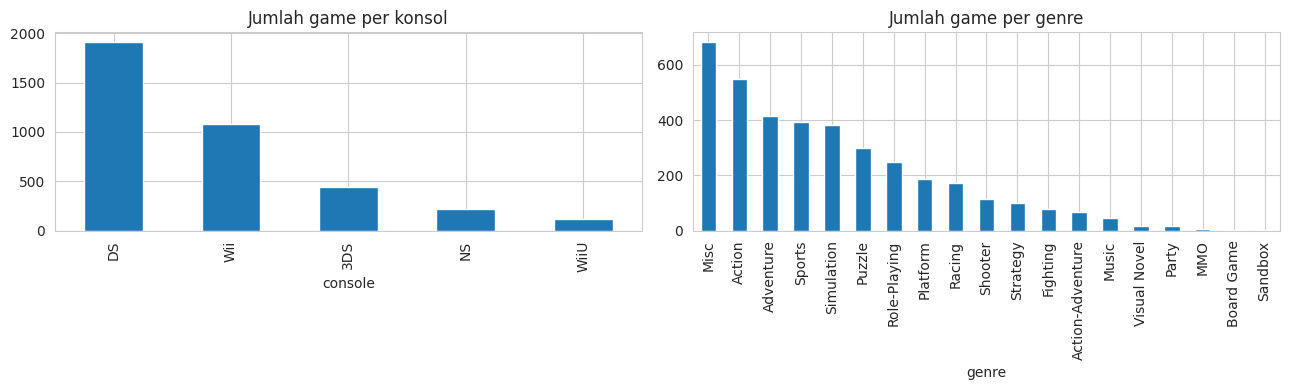

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
train["console"].value_counts().plot(kind="bar", ax=ax[0], title="Jumlah game per konsol")
train["genre"].value_counts().plot(kind="bar", ax=ax[1], title="Jumlah game per genre")
plt.tight_layout(); plt.show()

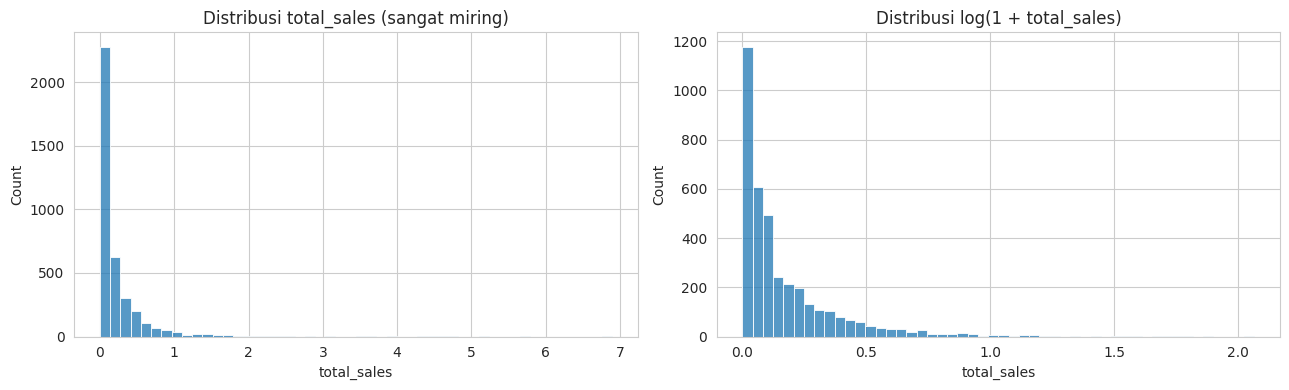

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["total_sales"], bins=50, ax=ax[0]).set_title("Distribusi total_sales (sangat miring)")
sns.histplot(np.log1p(train["total_sales"]), bins=50, ax=ax[1]).set_title("Distribusi log(1 + total_sales)")
plt.tight_layout(); plt.show()

Batas atas IQR: 0.580 juta | jumlah outlier: 345 (9.1%)


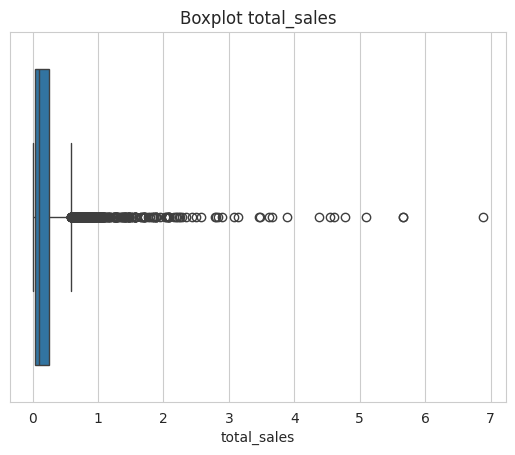

In [18]:
q1, q3 = train["total_sales"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
n_out = (train["total_sales"] > batas_atas).sum()
print(f"Batas atas IQR: {batas_atas:.3f} juta | jumlah outlier: {n_out} ({n_out/len(train)*100:.1f}%)")
sns.boxplot(x=train["total_sales"]); plt.title("Boxplot total_sales"); plt.show()

In [19]:
print(train.groupby("console")["total_sales"].agg(["count", "mean", "median", "sum"]).round(3), "\n")
print(train.groupby("genre")["total_sales"].agg(["count", "mean", "sum"]).sort_values("sum", ascending=False).round(3).head(10))

         count   mean  median     sum
console                              
3DS        445  0.179    0.09   79.56
DS        1913  0.185    0.08  353.89
NS         218  0.146    0.05   31.84
Wii       1085  0.338    0.15  367.15
WiiU       119  0.247    0.13   29.34 

              count   mean     sum
genre                             
Misc            683  0.239  163.05
Action          547  0.231  126.09
Sports          394  0.281  110.89
Simulation      383  0.253   96.99
Adventure       414  0.193   79.97
Platform        188  0.260   48.92
Role-Playing    250  0.188   46.96
Puzzle          298  0.147   43.74
Racing          173  0.196   33.99
Shooter         114  0.244   27.84


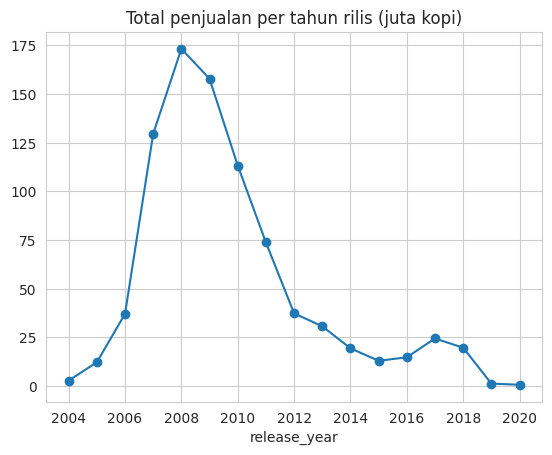

In [20]:
tren = train.groupby("release_year")["total_sales"].sum()
tren[tren.index > 1990].plot(kind="line", marker="o", title="Total penjualan per tahun rilis (juta kopi)")
plt.show()

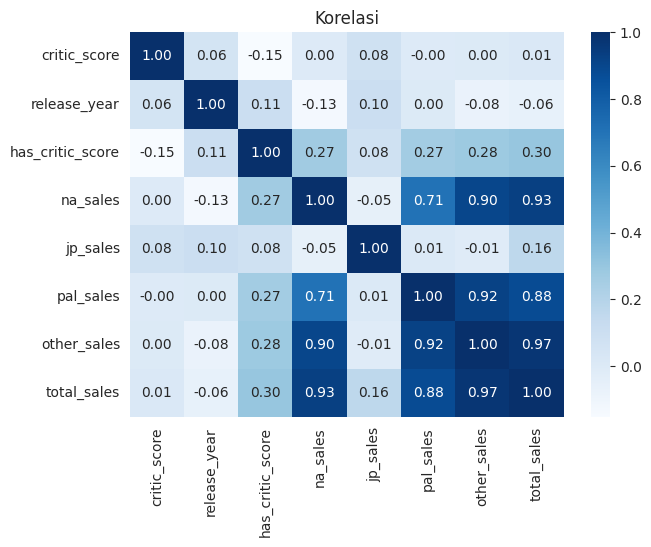

In [21]:
num_cols = ["critic_score", "release_year", "has_critic_score"] + SALES_COLS + ["total_sales"]
plt.figure(figsize=(7, 5))
sns.heatmap(train[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Korelasi"); plt.show()

In [22]:
FITUR_KAT = ["console", "genre", "publisher_grp"]
FITUR_NUM = ["release_year", "critic_score", "has_critic_score"]

X_train, X_test = train[FITUR_KAT + FITUR_NUM], test[FITUR_KAT + FITUR_NUM]
y_train, y_test = train["total_sales"], test["total_sales"]
y_train_log = np.log1p(y_train)

prep = ColumnTransformer([
    ("kat", OneHotEncoder(handle_unknown="ignore"), FITUR_KAT),
    ("num", "passthrough", FITUR_NUM),
])

In [23]:
def evaluasi(nama, y_true, y_pred):
    return {
        "Model": nama,
        "MAE (juta)": mean_absolute_error(y_true, y_pred),
        "RMSE (juta)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

hasil = []

# Baseline: tebak median train
base_pred = np.full(len(y_test), y_train.median())
hasil.append(evaluasi("Baseline (median)", y_test, base_pred))

# Linear Regression
lin = Pipeline([("prep", prep), ("model", LinearRegression())]).fit(X_train, y_train_log)
hasil.append(evaluasi("Linear Regression", y_test, np.expm1(lin.predict(X_test)).clip(min=0)))

# Random Forest
rf = Pipeline([("prep", prep),
               ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                               random_state=SEED, n_jobs=-1))]).fit(X_train, y_train_log)
rf_pred = np.expm1(rf.predict(X_test)).clip(min=0)
hasil.append(evaluasi("Random Forest", y_test, rf_pred))

pd.DataFrame(hasil).round(3)

,Model,MAE (juta),RMSE (juta),R2
0,Baseline (median),0.202,0.420,-0.124
1,Linear Regression,0.183,0.359,0.181
2,Random Forest,0.184,0.342,0.255


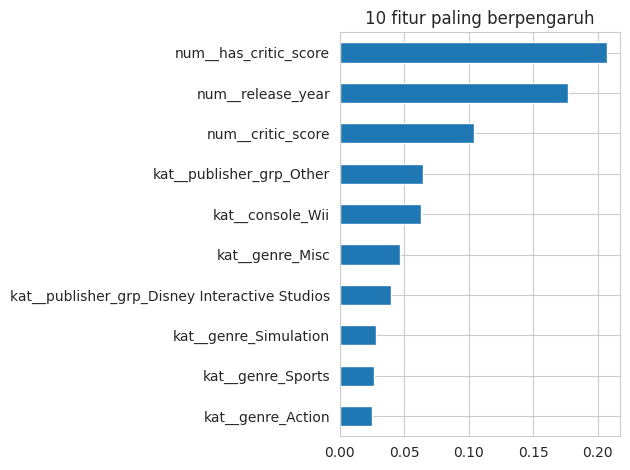

In [24]:
nama_fitur = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=nama_fitur).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh", title="10 fitur paling berpengaruh")
plt.tight_layout(); plt.show()

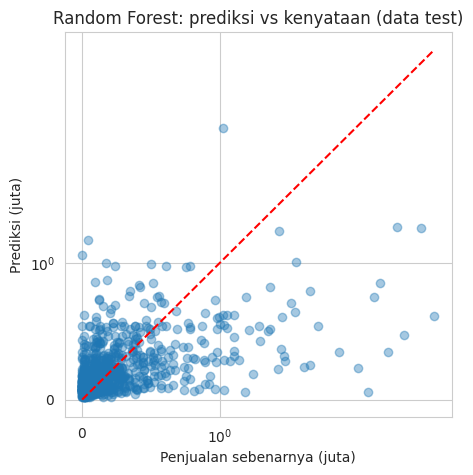

In [25]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, rf_pred, alpha=0.4)
mx = max(y_test.max(), rf_pred.max())
plt.plot([0, mx], [0, mx], "r--")
plt.xscale("symlog"); plt.yscale("symlog")
plt.xlabel("Penjualan sebenarnya (juta)"); plt.ylabel("Prediksi (juta)")
plt.title("Random Forest: prediksi vs kenyataan (data test)")
plt.show()